<center>

$\Huge \textbf{Universidad Tecmilenio}$  
<p align="center">
  <img src="https://sic.cultura.gob.mx/images/135155" alt="Tecmilenio" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Actividad 5}$  

$\Large \textit{Gestión de proyectos de Inteligencia Artifical}$    

\begin{array}{rl}
\textbf{Docente:} \text{ ELISKAR ROGER ALTAMIRANO }  \\[6pt]
\textbf{Alumno:} \text{ Mariana  Ramirez Jimenez} \\[6pt]
\textbf{Fecha de entrega:} & 17/10/2026
\end{array}

</center>
---

In [1]:
!pip install mlflow scikit-learn pandas numpy matplotlib seaborn -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 73.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.sklearn

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Descripción del dataset
print(df.shape)

df.info()

df.describe()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
#Valores nulos
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [6]:
#Limpieza de datos
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

df = df.drop(
    columns=["Cabin", "Name", "Ticket", "PassengerId"]
)

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [7]:
#Variables categoricas
df = pd.get_dummies(
    df,
    columns=["Sex", "Embarked"],
    drop_first=True
)

df.head()


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [8]:
#Variables predictorias
X = df.drop("Survived", axis=1)

y = df["Survived"]

print(X.shape)

(891, 8)


In [9]:
#Escalado
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

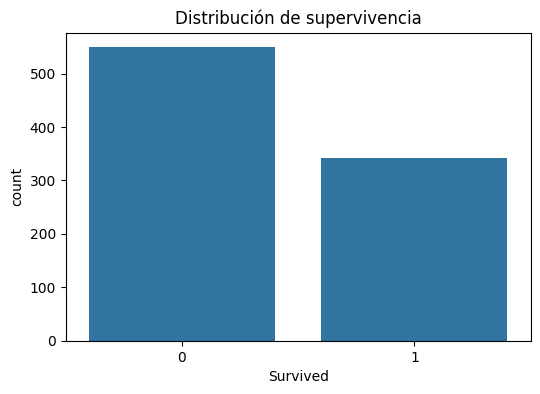

In [10]:
#Distribución de supervivencia
plt.figure(figsize=(6,4))

sns.countplot(
    x="Survived",
    data=df
)

plt.title("Distribución de supervivencia")

plt.show()

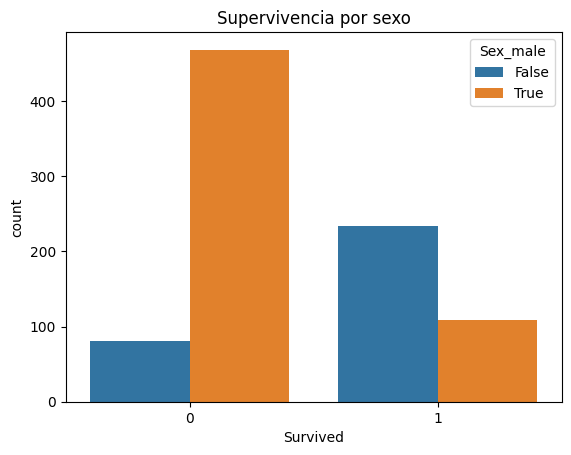

In [11]:
#Supervivencia por sexo
sns.countplot(
    x="Survived",
    hue="Sex_male",
    data=df
)

plt.title("Supervivencia por sexo")
plt.show()

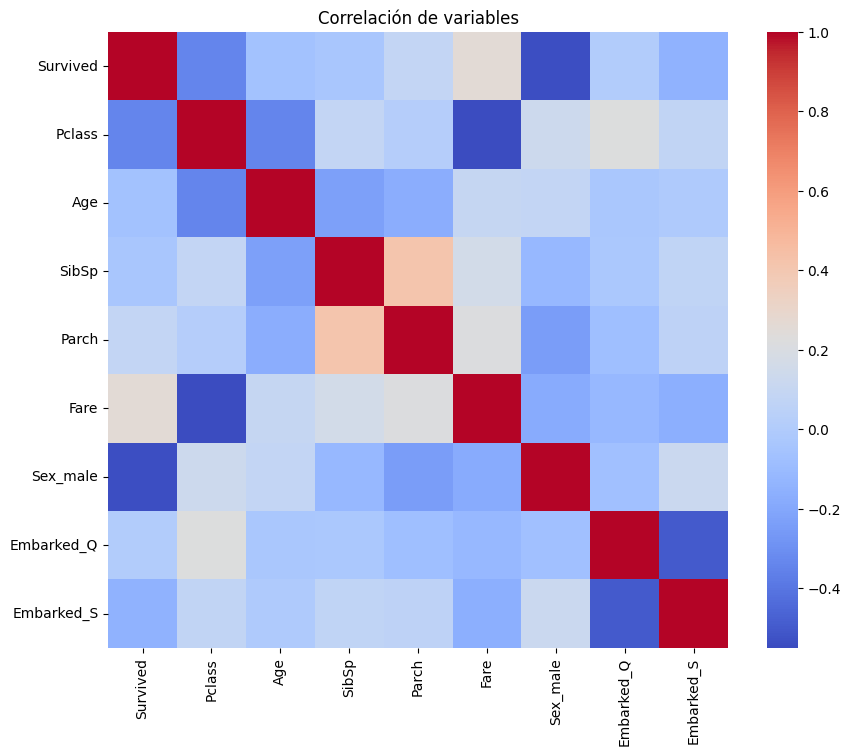

In [12]:
#Mapa de correlación
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    cmap="coolwarm"
)

plt.title("Correlación de variables")

plt.show()

In [13]:
#División de datos
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(712, 8)
(179, 8)


In [14]:
#Configuración MLflow
mlflow.set_experiment(
    "Actividad5_MLOps"
)

2026/10/18 03:05:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 03:05:44 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 03:05:49 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_MLOps' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1792292749059, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792292749059, lifecycle_stage='active', name='Actividad5_MLOps', tags={}, trace_location=None, workspace='default'>

In [15]:
#Modelo de regresión logistica
param_grid_lr = {
    "C":[0.01,0.1,1,10,100]
}

grid_lr = GridSearchCV(
    LogisticRegression(),
    param_grid_lr,
    cv=5,
    scoring="accuracy"
)

grid_lr.fit(
    X_train,
    y_train
)

best_lr = grid_lr.best_estimator_

print(grid_lr.best_params_)

{'C': 0.01}


In [16]:
#validación cruzada
cv_scores_lr = cross_val_score(
    best_lr,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print(cv_scores_lr)
print(cv_scores_lr.mean())

[0.7972028  0.76923077 0.83802817 0.83098592 0.79577465]
0.8062444597655866


In [17]:
#Evaluación
pred_lr = best_lr.predict(X_test)

acc_lr = accuracy_score(y_test,pred_lr)

prec_lr = precision_score(y_test,pred_lr)

rec_lr = recall_score(y_test,pred_lr)

f1_lr = f1_score(y_test,pred_lr)

roc_lr = roc_auc_score(y_test,pred_lr)

print("Accuracy:",acc_lr)
print("Precision:",prec_lr)
print("Recall:",rec_lr)
print("F1:",f1_lr)
print("ROC-AUC:",roc_lr)

Accuracy: 0.8044692737430168
Precision: 0.84
Recall: 0.6086956521739131
F1: 0.7058823529411765
ROC-AUC: 0.7679841897233202


In [22]:
#Registro en MLFLOW
with mlflow.start_run(
    run_name="LogisticRegression"
):

    mlflow.log_param(
        "modelo",
        "LogisticRegression"
    )

    mlflow.log_param(
        "C",
        grid_lr.best_params_["C"]
    )

    mlflow.log_metric("accuracy",acc_lr)
    mlflow.log_metric("precision",prec_lr)
    mlflow.log_metric("recall",rec_lr)
    mlflow.log_metric("f1",f1_lr)
    mlflow.log_metric("roc_auc",roc_lr)

    mlflow.sklearn.log_model(
        sk_model=best_lr,
        artifact_path="modelo"
    )

2026/10/18 03:13:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [23]:
#Random forest
param_grid_rf = {

    "n_estimators":[50,100,200],

    "max_depth":[
        3,
        5,
        10,
        None
    ]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(
        random_state=42
    ),
    param_grid_rf,
    cv=5,
    scoring="accuracy"
)

grid_rf.fit(
    X_train,
    y_train
)

best_rf = grid_rf.best_estimator_

print(grid_rf.best_params_)

{'max_depth': 3, 'n_estimators': 100}


In [24]:
#Validación cruzada
cv_scores_rf = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print(cv_scores_rf)

print(
    cv_scores_rf.mean()
)

[0.81818182 0.7972028  0.87323944 0.86619718 0.82394366]
0.8357529794149514


In [25]:
#evaluación
pred_rf = best_rf.predict(X_test)

acc_rf = accuracy_score(
    y_test,
    pred_rf
)

prec_rf = precision_score(
    y_test,
    pred_rf
)

rec_rf = recall_score(
    y_test,
    pred_rf
)

f1_rf = f1_score(
    y_test,
    pred_rf
)

roc_rf = roc_auc_score(
    y_test,
    pred_rf
)

print("Accuracy:",acc_rf)
print("Precision:",prec_rf)
print("Recall:",rec_rf)
print("F1:",f1_rf)
print("ROC-AUC:",roc_rf)

Accuracy: 0.7932960893854749
Precision: 0.8636363636363636
Recall: 0.5507246376811594
F1: 0.672566371681416
ROC-AUC: 0.7480895915678525


In [27]:
#Registro en MLFLOW
with mlflow.start_run(
    run_name="RandomForest"
):

    mlflow.log_param(
        "modelo",
        "RandomForest"
    )

    for k,v in grid_rf.best_params_.items():

        mlflow.log_param(
            k,
            v
        )

    mlflow.log_metric(
        "accuracy",
        acc_rf
    )

    mlflow.log_metric(
        "precision",
        prec_rf
    )

    mlflow.log_metric(
        "recall",
        rec_rf
    )

    mlflow.log_metric(
        "f1",
        f1_rf
    )

    mlflow.log_metric(
        "roc_auc",
        roc_rf
    )

    mlflow.sklearn.log_model(
        sk_model=best_rf,
        artifact_path="modelo",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

2026/10/18 03:15:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [28]:
#Comparación de modelos
resultados = pd.DataFrame({

    "Modelo":[
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy":[
        acc_lr,
        acc_rf
    ],

    "Precision":[
        prec_lr,
        prec_rf
    ],

    "Recall":[
        rec_lr,
        rec_rf
    ],

    "F1":[
        f1_lr,
        f1_rf
    ],

    "ROC_AUC":[
        roc_lr,
        roc_rf
    ]
})

resultados

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.804469,0.840000,0.608696,0.705882,0.767984
1,Random Forest,0.793296,0.863636,0.550725,0.672566,0.748090


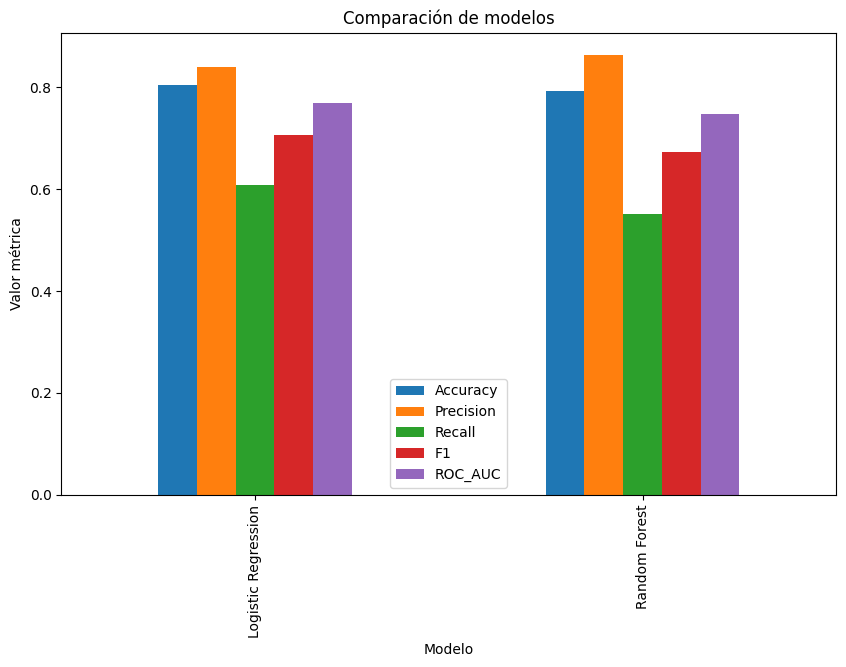

In [29]:
#Grafica comparativa
resultados.set_index(
    "Modelo"
).plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Comparación de modelos"
)

plt.ylabel(
    "Valor métrica"
)

plt.show()

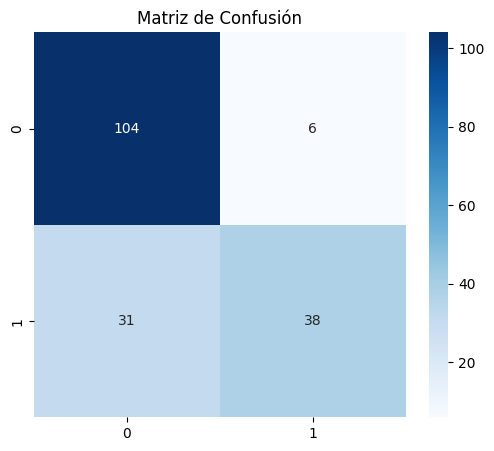

In [30]:
#Matriz de confunsión

mejor_modelo = best_rf

pred = mejor_modelo.predict(
    X_test
)

cm = confusion_matrix(
    y_test,
    pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Matriz de Confusión"
)

plt.show()

In [31]:
#reporte de clasificación
print(
    classification_report(
        y_test,
        pred
    )
)

              precision    recall  f1-score   support

           0       0.77      0.95      0.85       110
           1       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179



In [32]:
#Mostrar experimento MLFlow
!mlflow ui --host 0.0.0.0 --port 5000 &

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/18 03:18:34 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/18 03:18:34 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/18 03:18:35 INFO:     Uvicorn running on http://0.0.0.0:5000 (Press CTRL+C to quit)
2026/10/18 03:18:35 INFO:     Started parent process [6763]
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_